In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [33]:
sns.set_theme(style="whitegrid", palette="muted")

In [34]:
import pandas as pd

path = "DataYuma.xlsx"
dataraw = pd.read_excel(path)

styled_dataraw = dataraw.style.background_gradient(
    subset=['Quiz', 'UTS', 'UAS', 'Nilai'], cmap='Blues'
).set_properties(**{
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center'), ('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'td', 'props': [('font-family', 'sans-serif')]}
]).format({
    'Nilai': '{:.2f}'
})

display(styled_dataraw)

,ID,Name,Quiz,UTS,UAS,Nilai,Grade
0,2455301199,Yuma Wisesa Jigme,90,82,79,83.51,A
1,120001,John Doe,85,78,90,84.44,A
2,120005,Jane Smith,92,88,94,91.38,A
3,120017,Michael Johnson,48,65,56,56.41,C
4,120018,Emily Brown,90,85,88,87.65,A
5,120022,Daniel Martinez,75,80,77,77.35,AB
6,120024,Sarah Wilson,88,70,65,74.01,B
7,120025,David Garcia,75,70,75,73.35,B
8,120027,Jessica Lee,95,91,96,94.03,A
9,120034,Matthew Davis,79,84,78,80.30,AB


In [35]:
datafrq = pd.crosstab(index=dataraw["Grade"], columns=["Frekuensi"])
print(datafrq)

col_0  Frekuensi
Grade           
A             13
AB             7
B              4
BC             1
C              5
F              1


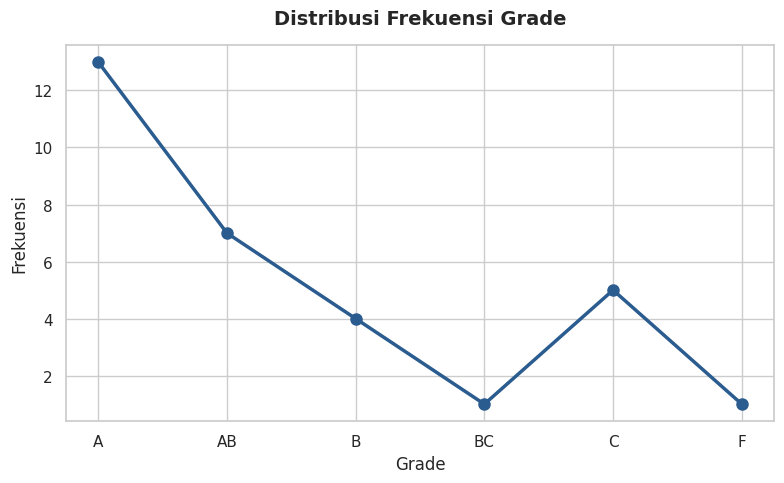

In [36]:
plt.figure(figsize=(8, 5))
datafrq['Frekuensi'].plot(kind='line', marker='o', color='#2b5c8f', linewidth=2.5, markersize=8)
plt.title('Distribusi Frekuensi Grade', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grade', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.tight_layout()
plt.show()

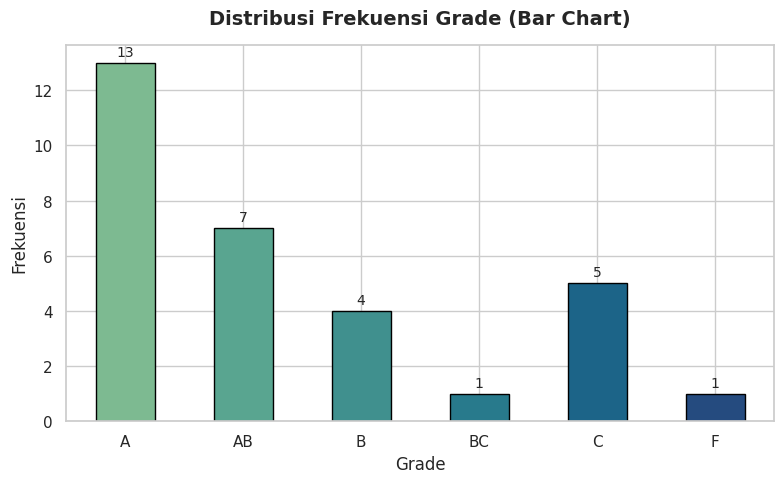

In [37]:
plt.figure(figsize=(8, 5))
ax = datafrq['Frekuensi'].plot(kind='bar', color=sns.color_palette("crest", len(datafrq)), edgecolor='black', linewidth=1)
plt.title('Distribusi Frekuensi Grade (Bar Chart)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grade', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)
plt.xticks(rotation=0)
plt.bar_label(ax.containers[0], padding=3, fontsize=10)
plt.tight_layout()
plt.show()

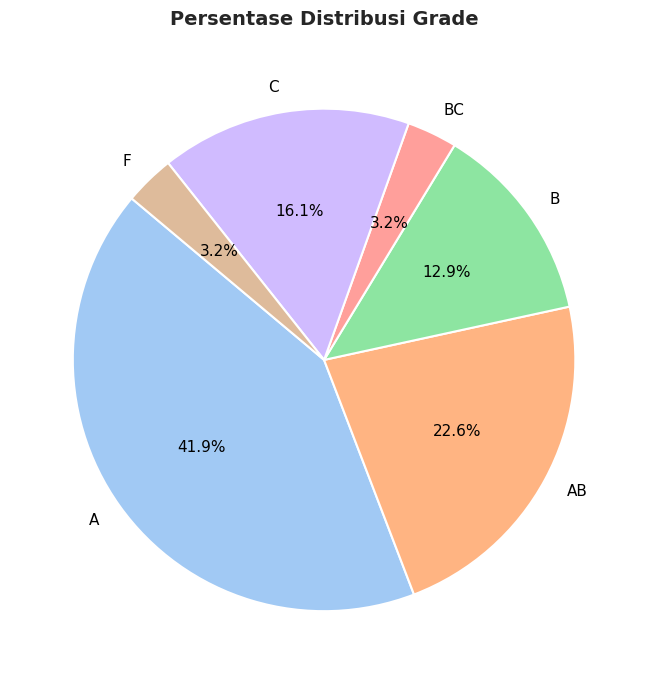

In [38]:
plt.figure(figsize=(7, 7))
colors = sns.color_palette('pastel')[0:len(datafrq)]
datafrq['Frekuensi'].plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=colors,
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    textprops={'fontsize': 11, 'color': 'black'}
)
plt.title('Persentase Distribusi Grade', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('')
plt.tight_layout()
plt.show()

In [39]:
dataraw["Nilai"] = pd.to_numeric(dataraw["Nilai"],errors='coerce')
dt = dataraw["Nilai"]
stats = dt.describe()
stats['Standard Error'] = dt.sem()
stats['Median'] = dt.median()
stats['Mode'] = dt.mode().iloc[0]
stats['variance'] = dt.var()
stats['range'] = dt.max() - dt.min()
stats['skewness'] = dt.skew()
stats['kurtosis'] = dt.kurtosis()

df_stats = stats.reset_index()
df_stats.columns = ['Statistik', 'Nilai']

styled_stats = df_stats.style.background_gradient(
    subset=['Nilai'], cmap='YlGnBu'
).hide(axis='index').set_properties(**{
    'text-align': 'left'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'left'), ('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'td', 'props': [('font-family', 'sans-serif')]}
]).format({
    'Nilai': '{:.4f}'
})

display(styled_stats)

Statistik,Nilai
count,31.0000
mean,76.4565
std,13.3048
min,46.0100
25%,68.8000
50%,79.3000
75%,86.7900
max,94.0300
Standard Error,2.3896
Median,79.3000
